In [17]:
from jupyter_tikz import TexFragment
import os, sys
from IPython.display import display, HTML, Markdown, Math

# To find local version of the library
sys.path.append('../src')

from pmule import PredecessorTable, ProjectGraph, pinta_tikz

In [18]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

In [19]:
import pandas as pd
import numpy as np

datos_enunciado= pd.DataFrame([
#actividad, precedentes, duracion, desviacion,  cur, recursos, duracion_tope
  (   'A',     '--- ',       5,         2,        5,      6,       1  ),
  (   'B',     '--- ',       2,         1,        5,      4,       1  ),
  (   'C',     'B   ',       6,         2,       25,      20,       2  ),
  (   'D',     'A   ',       2,         1,      -10,      5,       1  ),
  (   'E',     'A   ',       3,         0,        1,      3,       4  ),
  (   'F',     'E   ',       3,         1,        5,      7,       2  ),
  (   'G',     'C,D ',       1,         0,      -20,      2,       1  ),
  (   'H',     'C,D ',       2,         3,        1,      8,       2  ),
  (   'I',     'F,G,H',      1,         0,        1,      2,       1  ),
  (   'J',     'F,G  ',      2,         0,       -1,      7,       2 ),
  (   'K',     'F,G  ',      1,         0,        5,      3,       1  ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation', 'ucr', 'resources', 'cap_duration']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation,ucr,resources,cap_duration
activity,,,,,,
A,---,5,2,5,6,1
B,---,2,1,5,4,1
C,B,6,2,25,20,2
D,A,2,1,-10,5,1
E,A,3,0,1,3,4
F,E,3,1,5,7,2
G,"C,D",1,0,-20,2,1
H,"C,D",2,3,1,8,2
I,"F,G,H",1,0,1,2,1


# Solución
## Apartado 1

In [20]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')

In [21]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto_apartado_1 = datos_proyecto.copy() # La necesitaremos en el apartado 4

In [22]:
proyecto = prelaciones.create_project()

In [23]:
holguras = proyecto.calculate_pert(durations=datos_proyecto['duration'])['activities'].T

In [24]:
proyecto_nivelacion = proyecto.copy()

desplazamientos, cuadrados, my_data, gantt_df, dibujo = proyecto_nivelacion.nivelar(data=datos_proyecto,
                           duration_label='duration',
                           resource_label='resources',
                           #report=False
                           )

In [26]:
cuadrados

,0,1,2,3
activity,,,,
B,5081,5121,5197,
D,5081,5081,4921,4797
C,4797,5037,5277,
G,4797,,,
H,4797,,,
I,4797,,,
K,4797,4761,,


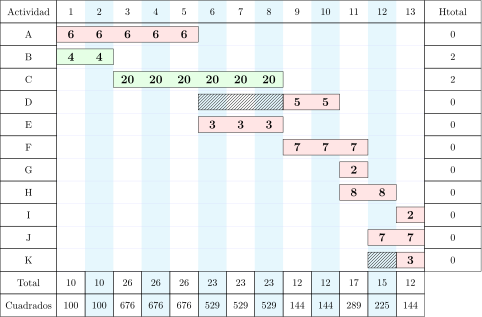

In [27]:
pinta_tikz(dibujo)

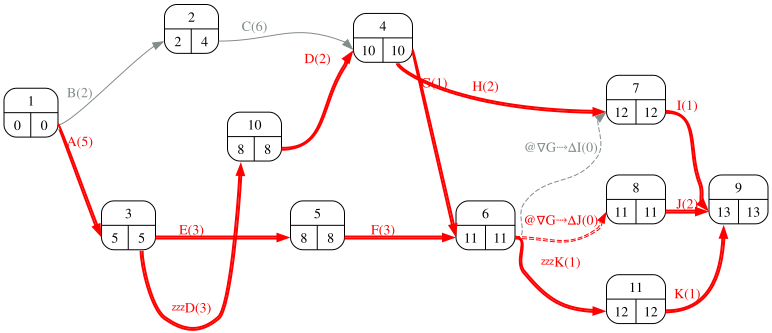

In [28]:
proyecto_nivelacion.pert(ranksep=0.25, nodesep=0.7, durations=my_data['duration'])